# Facebook Comment Volume Prediction – Keras / TensorFlow (Regression)
**Dataset:** `Features_Variant_1.csv` (UCI Facebook Comment Volume) | **Target:** post par kitne comments aayenge (number)

**Steps:** Data load → EDA (seaborn/matplotlib) → Cleaning → Log transform + Split + Scale → Baseline → Neural Network (3 versions) → Evaluation → Conclusion

> Ye **regression** hai: target ek number hai (0, 5, 300...), koi category nahi. Isliye output layer mein **1 node, koi activation nahi**, loss = `mse`.
>
> Is notebook mein **har code line ke saath Hinglish comment** hai, taaki har line ka matlab samajh aaye.

## 1. Libraries

In [2]:
import numpy as np                                    # numpy: numbers aur maths ke liye, 'np' short naam se
import pandas as pd                                   # pandas: data ko table (DataFrame) mein rakhne ke liye
import matplotlib.pyplot as plt                       # matplotlib: charts banane ke liye
import seaborn as sns                                 # seaborn: matplotlib ke upar sundar charts ke liye
import tensorflow as tf                               # tensorflow: deep learning ka main engine
from tensorflow import keras                          # keras: tensorflow ke andar model banane ki aasaan library
from tensorflow.keras import layers                   # layers: Dense jaise layers yahin se aate hain
from sklearn.model_selection import train_test_split  # data ko train aur test mein baantne ke liye
from sklearn.preprocessing import StandardScaler      # features ko ek jaise scale par laane ke liye
from sklearn.linear_model import LinearRegression     # baseline ke liye seedhi line wala model
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score  # regression ke scores nikalne ke liye

sns.set_theme(style="whitegrid")                      # seaborn ka saaf-suthra white grid look laga do
np.random.seed(42)                                    # numpy ka random fix karo taaki har baar same result aaye
tf.random.set_seed(42)                                # tensorflow ka random bhi fix karo (reproducibility)

## 2. Data load karo

In [3]:
df = pd.read_csv("Features_Variant_1.csv", header=None)  # CSV padho; header=None kyunki file mein column names nahi hain
print("Shape:", df.shape)                                # (rows, columns) print karo

Shape: (40949, 54)


In [4]:
df = pd.read_csv('Features_Variant_1.csv', header=None)


In [5]:
df.shape

(40949, 54)

In [6]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,44,45,46,47,48,49,50,51,52,53
0,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,0,1,0
1,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,1,0,0
2,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,0,0,0,0,0,1,0
3,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,1,0,0,0,0,0,0
4,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,1,0,0,0,0


In [7]:
# UCI ke documentation ke hisaab se columns ko naam de do (padhne mein aasaani)
cols = (["page_likes", "page_checkins", "page_talking_about", "page_category"]   # column 0-3: page ki jaankari
        + [f"derived_{i:02d}" for i in range(1, 26)]                               # column 4-28: 25 derived features (min/max/avg type)
        + ["cc1_total_before", "cc2_last_24h", "cc3_24_48h",                       # column 29-31: pehle ke comments ki ginti
           "cc4_first_24h_after", "cc5_cc2_minus_cc3"]                             # column 32-33: baaki comment features
        + ["base_time_hours", "post_length", "post_share_count",                   # column 34-36: time, post ki lambai, shares
           "promotion_status", "h_local"]                                          # column 37-38: promotion status, local time
        + [f"pub_day_{d}" for d in ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]   # column 39-45: post kis din publish hui
        + [f"base_day_{d}" for d in ["sun", "mon", "tue", "wed", "thu", "fri", "sat"]]  # column 46-52: base time ka din
        + ["target_comments"])                                                     # column 53: TARGET (comments ki sankhya)
df.columns = cols                                    # ye naam DataFrame ke columns bana do
print("Columns ki sankhya:", len(cols))              # total columns check karo
df.head()                                            # pehli 5 rows dekho

Columns ki sankhya: 54


,page_likes,page_checkins,page_talking_about,page_category,derived_01,derived_02,derived_03,derived_04,derived_05,derived_06,...,pub_day_fri,pub_day_sat,base_day_sun,base_day_mon,base_day_tue,base_day_wed,base_day_thu,base_day_fri,base_day_sat,target_comments
0,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,0,1,0
1,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,0,0,1,0,0
2,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,0,0,0,0,0,1,0
3,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,1,0,0,1,0,0,0,0,0,0
4,634995,0,463,1,0.0,806.0,11.291045,1.0,70.495138,0.0,...,0,0,0,0,0,1,0,0,0,0


In [8]:
df.info()                                            # har column ka data type aur non-null count dikhao

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40949 entries, 0 to 40948
Data columns (total 54 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   page_likes           40949 non-null  int64  
 1   page_checkins        40949 non-null  int64  
 2   page_talking_about   40949 non-null  int64  
 3   page_category        40949 non-null  int64  
 4   derived_01           40949 non-null  float64
 5   derived_02           40949 non-null  float64
 6   derived_03           40949 non-null  float64
 7   derived_04           40949 non-null  float64
 8   derived_05           40949 non-null  float64
 9   derived_06           40949 non-null  float64
 10  derived_07           40949 non-null  float64
 11  derived_08           40949 non-null  float64
 12  derived_09           40949 non-null  float64
 13  derived_10           40949 non-null  float64
 14  derived_11           40949 non-null  float64
 15  derived_12           40949 non-null 

In [9]:
print("Total null values:", df.isnull().sum().sum())     # saare columns ke missing values ka total
print("Duplicate rows   :", df.duplicated().sum())       # kitni rows bilkul ek jaisi hain
df[["page_likes", "cc1_total_before", "post_length", "post_share_count", "target_comments"]].describe()  # kuch columns ka mean/min/max/std

Total null values: 0
Duplicate rows   : 8


,page_likes,cc1_total_before,post_length,post_share_count,target_comments
count,4.094900e+04,40949.000000,40949.000000,40949.000000,40949.000000
mean,1.313814e+06,55.720384,163.652470,117.249823,7.322889
std,6.785752e+06,136.975705,376.264387,945.006667,35.494550
min,3.600000e+01,0.000000,0.000000,1.000000,0.000000
25%,3.673400e+04,2.000000,38.000000,2.000000,0.000000
50%,2.929110e+05,11.000000,97.000000,13.000000,0.000000
75%,1.204214e+06,46.000000,172.000000,61.000000,3.000000
max,4.869723e+08,2341.000000,21480.000000,144860.000000,1305.000000


## 3. EDA – target ko samjho

Zero comments wale posts: 55.1%
Median: 0.0 | Mean: 7.32 | Max: 1305


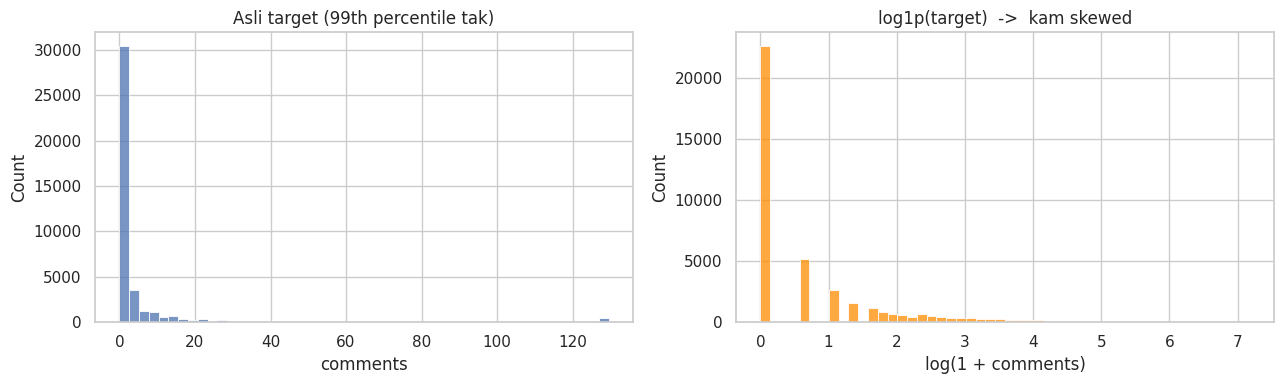

In [10]:
y_raw = df["target_comments"]                                                  # target column ko alag variable mein rakho
print("Zero comments wale posts: {:.1f}%".format((y_raw == 0).mean() * 100))   # kitne % posts par 0 comments hain
print("Median:", y_raw.median(), "| Mean:", round(y_raw.mean(), 2), "| Max:", y_raw.max())  # median, average aur sabse bada value

fig, ax = plt.subplots(1, 2, figsize=(13, 4))                                  # 1 row, 2 charts wali figure banao
sns.histplot(y_raw.clip(upper=y_raw.quantile(0.99)), bins=50, ax=ax[0])        # 99th percentile tak ka histogram (outliers kaat ke)
ax[0].set_title("Asli target (99th percentile tak)")                           # pehle chart ka title
ax[0].set_xlabel("comments")                                                   # x-axis ka naam
sns.histplot(np.log1p(y_raw), bins=50, ax=ax[1], color="darkorange")           # log1p ke baad ka histogram
ax[1].set_title("log1p(target)  ->  kam skewed")                               # doosre chart ka title
ax[1].set_xlabel("log(1 + comments)")                                          # x-axis ka naam
plt.tight_layout()                                                             # charts ek-doosre par na chadhein
plt.show()                                                                     # charts screen par dikhao

**Observation:** target bahut **skewed** hai. Zyadatar posts par 0-3 comments aate hain aur kuch posts viral ho jaate hain (hazaaron comments).
Isliye neural network ko seedha asli target par train karne ki jagah hum `np.log1p(y)` par train karenge, aur baad mein `np.expm1` se wapas asli scale par laayenge.

cc2_last_24h           0.582
derived_18             0.489
derived_03             0.488
derived_05             0.488
derived_20             0.484
derived_25             0.484
derived_13             0.478
derived_15             0.477
cc4_first_24h_after    0.476
derived_08             0.474
derived_10             0.467
cc1_total_before       0.465
Name: log_target, dtype: float64


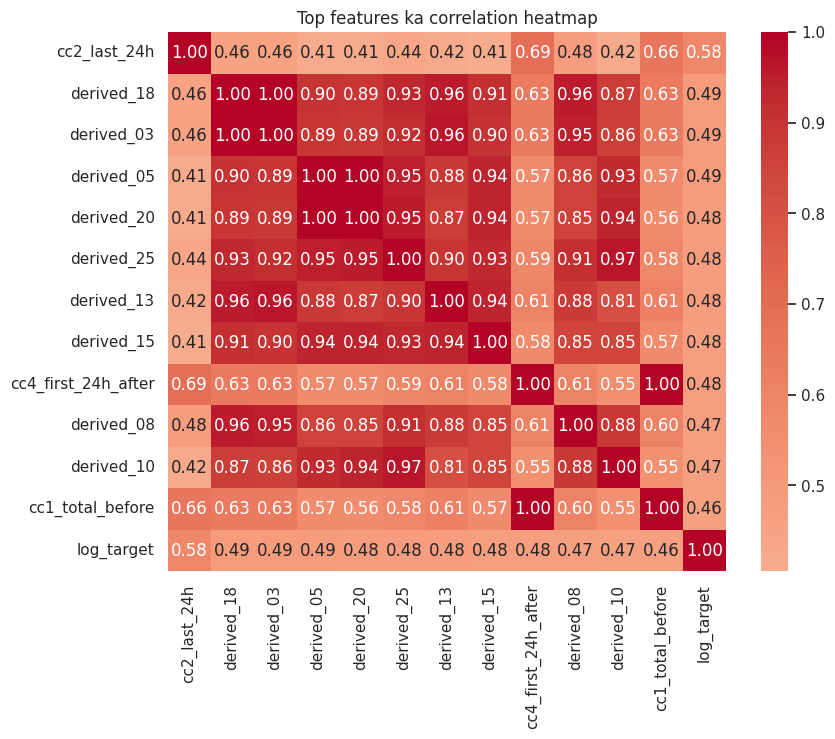

In [11]:
tmp = df.copy()                                                      # asli df ko chhede bina copy par kaam karo
tmp["log_target"] = np.log1p(tmp["target_comments"])                 # target ka log1p nikalo
corr = tmp.drop(columns="target_comments").corr()["log_target"].drop("log_target")   # har feature ka log_target se correlation
top = corr.abs().sort_values(ascending=False).head(12)               # sabse zyada related 12 features chuno
print(corr[top.index].round(3))                                      # unke correlation values print karo

plt.figure(figsize=(9, 7))                                           # chart ka size set karo
sns.heatmap(tmp[list(top.index) + ["log_target"]].corr(),            # top features + target ka correlation matrix
            annot=True, fmt=".2f", cmap="coolwarm", center=0)        # numbers dikhao, 2 decimal, laal-neela rang
plt.title("Top features ka correlation heatmap")                     # chart ka title
plt.show()

## 4. Data Cleaning

In [12]:
print("Duplicates:", df.duplicated().sum())     # kitni duplicate rows hain
print("Constant columns:", [c for c in df.columns if df[c].nunique() == 1])   # kaun se columns constant hain

Duplicates: 8
Constant columns: ['promotion_status']


## 5. Target transform, Split aur Scaling
- `y = log1p(comments)` (skew kam karne ke liye)
- 80% train, 20% test
- Scaler **train par fit**, test par sirf **transform** (data leakage se bachne ke liye)

In [13]:
X = df.drop(columns="target_comments").values        # target hata ke baaki sab columns = input features (X)
y = np.log1p(df["target_comments"].values)           # target ka log1p = y (jo model predict karega)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)   # 80% train, 20% test, fixed random

scaler = StandardScaler()                            # scaler object banao
X_train = scaler.fit_transform(X_train)              # train data se mean/std seekho (fit) aur scale karo (transform)
X_test = scaler.transform(X_test)                    # test par sirf transform, wahi train wala mean/std (leakage nahi)

print("Input features ki sankhya:", X_train.shape[1])            # kitne input features hain
print("Train:", X_train.shape, "| Test:", X_test.shape)          # train aur test ka shape

Input features ki sankhya: 53
Train: (32759, 53) | Test: (8190, 53)


## 6. Baseline models
Neural network ko tabhi "achha" bol sakte hain jab wo simple models se behtar ho.
- **Mean baseline:** hamesha train ka average predict karo (sabse bekaar model)
- **Linear Regression:** seedhi line wala model

In [14]:
results = []                                                       # saare models ke scores is list mein jama honge

In [15]:
def evaluate(name, y_true_log, y_pred_log):                        # function: model ka naam, asli aur predicted (log scale) lo
    y_pred_log = np.clip(np.ravel(y_pred_log), 0, None)            # predictions ko 1D karo aur 0 se neeche mat jaane do (comments negative nahi hote)
    rmse_log = np.sqrt(mean_squared_error(y_true_log, y_pred_log)) # log scale par RMSE (bade errors ko zyada saza)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)          # log scale par MAE (average error)
    r2_log = r2_score(y_true_log, y_pred_log)                      # log scale par R2 (1 ke jitna paas, utna behtar)
    y_true = np.expm1(y_true_log)                                  # log se wapas asli comments ki ginti mein badlo
    y_pred = np.expm1(y_pred_log)                                  # predictions ko bhi asli scale par laao
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))             # asli scale par RMSE
    mae = mean_absolute_error(y_true, y_pred)                      # asli scale par MAE (average kitne comments ka galat andaza)
    results.append({"Model": name, "RMSE (log)": rmse_log, "MAE (log)": mae_log, "R2 (log)": r2_log,   # saare scores ek dictionary mein
                    "RMSE (comments)": rmse, "MAE (comments)": mae})                                     # aur list mein daal do
    print(f"{name:22s} | R2(log): {r2_log:6.3f} | RMSE(log): {rmse_log:5.3f} | MAE(comments): {mae:6.2f} | RMSE(comments): {rmse:7.2f}")   # ek line mein result dikhao

In [16]:
evaluate("Mean Baseline", y_test, np.full_like(y_test, y_train.mean()))   # har test row ke liye train ka average predict karo

lin = LinearRegression().fit(X_train, y_train)                            # Linear Regression ko train data par train karo
evaluate("Linear Regression", y_test, lin.predict(X_test))                # test data par predict karo aur score nikalo

Mean Baseline          | R2(log): -0.000 | RMSE(log): 1.195 | MAE(comments):   7.19 | RMSE(comments):   33.20
Linear Regression      | R2(log):  0.579 | RMSE(log): 0.776 | MAE(comments): 145.14 | RMSE(comments): 10446.79


## 7. Neural Network models (Regression)
Teen architectures compare karenge:
1. **NN Linear** – 64→32→16→1 par `activation='linear'` (nonlinearity nahi, sirf comparison ke liye)
2. **NN ReLU Small** – 32→16→1
3. **NN ReLU Deep** – 64→32→16→1

Output layer: **1 node, koi activation nahi**. Loss: `mse`. Metric: `mae`.

In [17]:
def build_model(hidden=(64, 32, 16), activation="relu"):                      # function: hidden layers ke nodes aur activation lo
    model = keras.Sequential([layers.Input(shape=(X_train.shape[1],))])      # Sequential model banao, input layer = features ki sankhya
    for units in hidden:                                                      # har hidden layer ke liye loop
        model.add(layers.Dense(units, activation=activation))                 # ek Dense (hidden) layer jodo
    model.add(layers.Dense(1))                                                # output layer: 1 node, koi activation nahi (regression)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),       # Adam optimizer, learning rate 0.001
                  loss="mse",                                                 # loss: mean squared error (regression ke liye)
                  metrics=["mae"])                                            # saath mein MAE bhi dekhte raho
    return model                                                              # banaya hua model wapas do

model = build_model()                                                         # default (64, 32, 16) ReLU model banao
model.summary()                                                               # layers aur parameters ki table dikhao

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         3,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,081 (23.75 KB)

 Trainable params: 6,081 (23.75 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",                # EarlyStopping: validation loss par nazar rakho
                                           patience=10,                       # 10 epoch tak na sudhre toh training rok do
                                           restore_best_weights=True)         # aur sabse achhe weights wapas le lo

configs = {                                                                   # teeno models ki settings ek dictionary mein
    "NN Linear":     dict(hidden=(64, 32, 16), activation="linear"),          # bina nonlinearity wala (comparison ke liye)
    "NN ReLU Small": dict(hidden=(32, 16),     activation="relu"),            # chhota ReLU network
    "NN ReLU Deep":  dict(hidden=(64, 32, 16), activation="relu"),            # gehra ReLU network
}                                                                             # dictionary band

histories, models = {}, {}                                                    # training history aur trained models yahan rakhenge
for name, cfg in configs.items():                                             # har model ke liye ek-ek karke
    keras.backend.clear_session()                                             # purana model memory se saaf karo
    tf.random.set_seed(42)                                                    # har model ke liye same random seed
    m = build_model(**cfg)                                                    # settings ke hisaab se model banao
    h = m.fit(X_train, y_train, epochs=100, batch_size=64,                    # train karo: max 100 epochs, 64 rows ka batch
              validation_split=0.2,                                           # train ka 20% validation ke liye alag rakho
              callbacks=[early_stop], verbose=1)                              # EarlyStopping lagao, progress bar band
    histories[name], models[name] = h, m                                      # history aur model dono save karo
    print(f"{name:14s} -> {len(h.history['loss'])} epochs chale | best val_loss: {min(h.history['val_loss']):.4f}")   # kitne epoch chale aur best val_loss

Epoch 1/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.8092 - mae: 0.6255 - val_loss: 0.8102 - val_mae: 0.6134
Epoch 2/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.8020 - mae: 0.6180 - val_loss: 0.6853 - val_mae: 0.6000
Epoch 3/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7573 - mae: 0.6009 - val_loss: 0.6884 - val_mae: 0.5984
Epoch 4/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.7031 - mae: 0.6015 - val_loss: 0.6750 - val_mae: 0.5967
Epoch 5/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6330 - mae: 0.5875 - val_loss: 0.6847 - val_mae: 0.5966
Epoch 6/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6324 - mae: 0.5875 - val_loss: 0.6783 - val_mae: 0.5954
Epoch 7/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6283 - mae: 0.5859 - val_loss: 0.6814 - val_mae: 0.5958
Epoch 8/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6299 - mae: 0.5863 - val_loss: 0.6800 - val_mae: 0.5954
Epoch 9/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/